# Task 15, Notebook 12: Salary data audit, EDA, leakage and feature choice

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 15: Recommend fair pay bands  
**Objective:** Understand the salary training data, find where history may carry bias, and choose job-related features only.  
**Workflow stages covered in this notebook:** 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3_working | seed: 42


## Stage 1: Business Understanding

*What this stage is for:* Who needs this result and what decision it supports.

Pay is personal. A recommendation that copies past pay copies past unfairness. The output is **advice** to a manager and HR, as a range, never an offer.

## Stage 2: Problem Definition

*What this stage is for:* The exact prediction, ranking or measurement problem, its inputs and its output.

**Regression:** predict the annual fixed salary offered at hiring from job-related facts. **Output:** a low / mid / high band. A second job is a **fairness test**: do predictions or errors differ by gender or by career gap?

## Stage 3: Objective and Success Criteria

*What this stage is for:* What number or evidence shows the task is done well, decided before looking at results.

Fixed before results: beat the simple 'average by role' baseline; report MAE and R2; output a range whose coverage is close to the 80% it claims; measure gaps by gender and career gap with the supplied `group_gap()` and explain them; write the limits.

In [2]:
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr.phase3.salary import model as S, run as SR
from cortexhr.phase3.explanations.risk_report import load_helpers
H = load_helpers()
sal = read_csv('salary_training'); df = S.load_salary(); dd = read_csv('data_dictionary')
print('salary rows:', sal.shape, '| engineered:', df.shape)

salary rows: (2934, 17) | engineered: (2934, 20)


In [3]:
pd.Series(CFG['salary']['success_criteria'], name='criterion').to_frame()

                                    criterion
must_beat_role_average_baseline_mae      True
band_target_coverage                      0.8
max_acceptable_band_coverage_error       0.05
output_is_a_range_not_one_number         True

## Stage 4: Dataset Discovery

*What this stage is for:* Which files exist, how they relate, and which are authoritative.

`salary_training` (2,934 historical hires) and, for measurement only, the restricted `unlock_CX-15` file with gender and age. The starter helper `group_gap()` is used for group gaps.

## Stage 5: Data Loading

*What this stage is for:* Load with the project helpers and check the load is complete.

In [4]:
va = S.vault_gender(); print('restricted attributes available:', va is not None); sal.head(3).T

restricted attributes available: True


                                            0                      1            2
hire_id                              EMP-0001               EMP-0002     EMP-0003
hire_date                          2012-01-19             2012-01-31   2012-03-08
hire_year                                2012                   2012         2012
department_id                             D01                    D01          D09
role_id                                  R002                   R007         R051
job_level                                   1                      4            2
band_min_2026                          400000                2000000       360000
band_mid_2026                          500000                2500000       450000
band_max_2026                          650000                3250000       585000
prior_experience_years                    0.0                   17.1          3.0
career_gap_months                           0                      9            0
work_location   

## Stage 6: Dataset Structure and Shape

*What this stage is for:* Rows, columns, keys and grain of each table.

One row per hire (`hire_id`).

In [5]:
print('rows:', len(sal), '| hire_id unique:', sal.hire_id.is_unique, '| hire years:', int(sal.hire_year.min()), 'to', int(sal.hire_year.max()), '| roles:', sal.role_id.nunique(), '| departments:', sal.department_id.nunique())

rows: 2934 | hire_id unique: True | hire years: 2012 to 2026 | roles: 47 | departments: 10


## Stage 7: Data Dictionary and Schema Understanding

*What this stage is for:* What each column means, from the supplied dictionary and from inspection.

In [6]:
dd[dd.sheet.str.contains('salary', case=False)][['column', 'data_type', 'description']]

                     column data_type                                                                                              description
174                 hire_id      text                                                                      Hire id (employee id or HIRE-nnnn).
175               hire_date      date                                                                                Date the employee joined.
176               hire_year   integer                                                                                            Year of hire.
177           department_id      text                                              Department code (D00 Executive ... D10 Legal & Compliance).
178                 role_id      text                                                                      Job role code from the roles table.
179               job_level   integer                                                            Level 1 to 7 (1 Associate ... 6 Head, 7 CEO).

## Stage 8: Data Type Inspection

*What this stage is for:* Check every column has the type it should have.

In [7]:
sal.dtypes.astype(str).to_frame('dtype').T

      hire_id hire_date hire_year department_id role_id job_level band_min_2026 band_mid_2026 band_max_2026 prior_experience_years career_gap_months work_location highest_education skills_count market_index offered_annual_fixed  source
dtype  object    object     int64        object  object     int64         int64         int64         int64                float64             int64        object            object        int64      float64                int64  object

## Stage 9: Data Quality Assessment

*What this stage is for:* A one-page quality profile before any modelling.

In [8]:
profile(sal)

                          dtype  missing  missing_pct  unique
hire_id                  object        0          0.0    2934
hire_date                object        0          0.0    1956
hire_year                 int64        0          0.0      15
department_id            object        0          0.0      10
role_id                  object        0          0.0      47
job_level                 int64        0          0.0       5
band_min_2026             int64        0          0.0      34
band_mid_2026             int64        0          0.0      34
band_max_2026             int64        0          0.0      34
prior_experience_years  float64        0          0.0     178
career_gap_months         int64        0          0.0       8
work_location            object        0          0.0       9
highest_education        object        0          0.0      27
skills_count              int64        0          0.0      14
market_index            float64        0          0.0    1951
offered_

## Stage 10: Missing Value Analysis

*What this stage is for:* Where values are missing, how much, and why that may be.

In [9]:
print('missing values per column:', sal.isna().sum()[lambda s: s > 0].to_dict() or 'none')

missing values per column: none


## Stage 11: Duplicate Analysis

*What this stage is for:* Exact and near duplicates of rows, keys and texts.

In [10]:
print('duplicate hire_id:', int(sal.hire_id.duplicated().sum()), '| exact duplicate rows:', int(sal.duplicated().sum()), '| duplicates ignoring hire_id/date:', int(sal.drop(columns=['hire_id', 'hire_date']).duplicated().sum()))

duplicate hire_id: 0 | exact duplicate rows: 0 | duplicates ignoring hire_id/date: 0


## Stage 12: Outlier Detection and Investigation

*What this stage is for:* Unusual values: are they errors or real?

salary IQR outliers: 134 (4.6%) on the raw scale, 0 on the log scale -> the raw skew is mostly the senior-level spread, not bad data


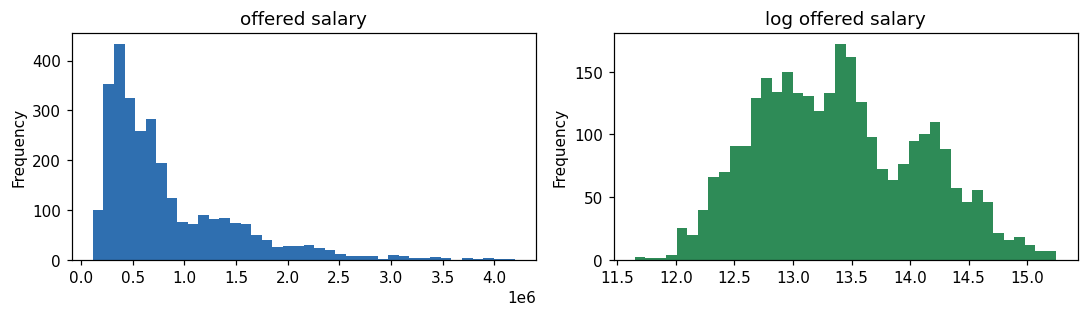

In [11]:
x = sal.offered_annual_fixed; q1, q3 = x.quantile([.25, .75]); i = q3 - q1; o = (x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)
lx = np.log(x); lo = (lx < lx.quantile(.25) - 1.5 * (lx.quantile(.75) - lx.quantile(.25))) | (lx > lx.quantile(.75) + 1.5 * (lx.quantile(.75) - lx.quantile(.25)))
print('salary IQR outliers: %d (%.1f%%) on the raw scale, %d on the log scale -> the raw skew is mostly the senior-level spread, not bad data' % (o.sum(), o.mean() * 100, lo.sum()))
fig, ax = plt.subplots(1, 2, figsize=(10, 3)); x.plot.hist(bins=40, ax=ax[0], color='#2f6fb0'); ax[0].set_title('offered salary'); lx.plot.hist(bins=40, ax=ax[1], color='#2e8b57'); ax[1].set_title('log offered salary'); plt.tight_layout()

## Stage 13: Invalid and Inconsistent Value Detection

*What this stage is for:* Impossible values, broken links between tables, label contradictions.

In [12]:
chk = {'salary > 0': bool((sal.offered_annual_fixed > 0).all()), 'band_min <= band_mid <= band_max': bool(((sal.band_min_2026 <= sal.band_mid_2026) & (sal.band_mid_2026 <= sal.band_max_2026)).all()),
       'career gap >= 0': bool((sal.career_gap_months >= 0).all()), 'prior experience between 0 and 45': bool(sal.prior_experience_years.between(0, 45).all()), 'market_index > 0': bool((sal.market_index > 0).all())}
print(pd.Series(chk, name='ok').to_frame().T.to_string()); print('offers outside the 2026 band range (after market adjustment): %.1f%%' % (100 * ((sal.offered_annual_fixed < sal.band_min_2026 * sal.market_index) | (sal.offered_annual_fixed > sal.band_max_2026 * sal.market_index)).mean()))

    salary > 0  band_min <= band_mid <= band_max  career gap >= 0  prior experience between 0 and 45  market_index > 0
ok        True                              True             True                               True              True
offers outside the 2026 band range (after market adjustment): 0.7%


## Stage 14: Exploratory Data Analysis (EDA)

*What this stage is for:* Look at the data before modelling.

In [13]:
df.groupby('job_level').offered_annual_fixed.agg(['count', 'median']).round(0)

           count     median
job_level                  
1            794   337056.0
2            997   576648.0
3            694  1098756.0
4            348  1748190.0
5            101  2720700.0

## Stage 15: Univariate Analysis

*What this stage is for:* One variable at a time.

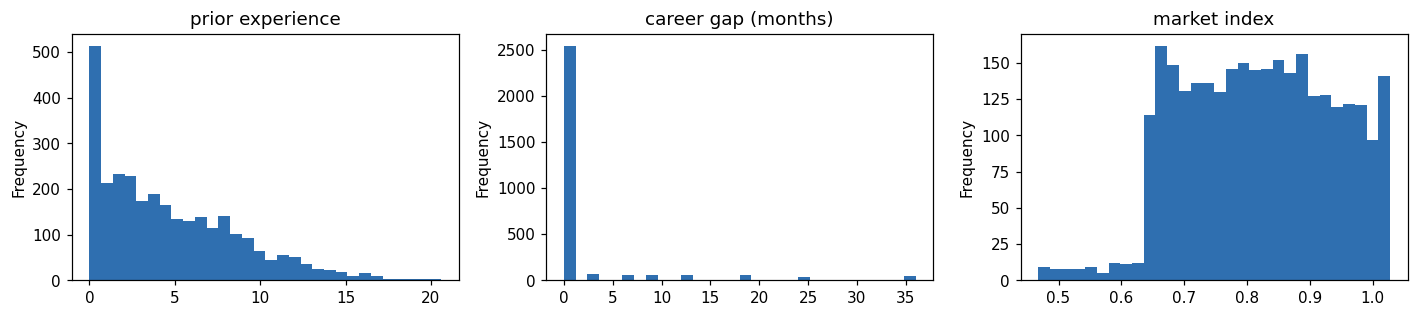

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3)); df.prior_experience_years.plot.hist(bins=30, ax=ax[0], color='#2f6fb0'); ax[0].set_title('prior experience'); df.career_gap_months.plot.hist(bins=30, ax=ax[1], color='#2f6fb0'); ax[1].set_title('career gap (months)'); df.market_index.plot.hist(bins=30, ax=ax[2], color='#2f6fb0'); ax[2].set_title('market index'); plt.tight_layout()

## Stage 16: Bivariate Analysis

*What this stage is for:* Two variables together, especially against the target or label.

The offer is almost proportional to **band mid-point x market index**. The ratio is the natural 'pay relative to the job' measure used in the fairness tests.

              count   mean    std   min    25%    50%    75%    max
pay_vs_band  2934.0  0.992  0.081  0.76  0.939  0.993  1.046  1.254

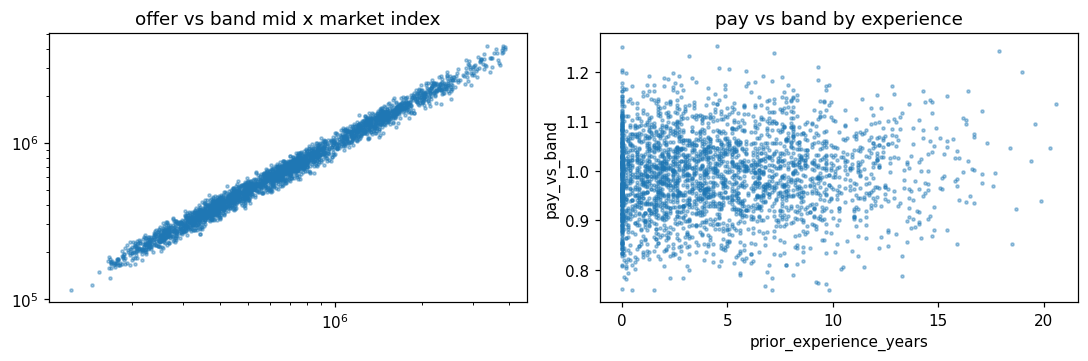

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); ax[0].scatter(df.band_mid_2026 * df.market_index, df.offered_annual_fixed, s=4, alpha=.4); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_title('offer vs band mid x market index')
df.plot.scatter('prior_experience_years', 'pay_vs_band', s=4, alpha=.4, ax=ax[1]); ax[1].set_title('pay vs band by experience'); plt.tight_layout()
df[['pay_vs_band']].describe().T.round(3)

## Stage 17: Multivariate Analysis

*What this stage is for:* Several variables together: correlation, interaction, redundancy.

In [16]:
df[['pay_vs_band', 'prior_experience_years', 'career_gap_months', 'skills_count', 'job_level', 'market_index']].corr(method='spearman').round(2)

                        pay_vs_band  prior_experience_years  career_gap_months  skills_count  job_level  market_index
pay_vs_band                    1.00                    0.06              -0.10         -0.04      -0.03          0.02
prior_experience_years         0.06                    1.00              -0.02          0.33       0.85          0.03
career_gap_months             -0.10                   -0.02               1.00          0.01      -0.02          0.01
skills_count                  -0.04                    0.33               0.01          1.00       0.40          0.01
job_level                     -0.03                    0.85              -0.02          0.40       1.00          0.03
market_index                   0.02                    0.03               0.01          0.01       0.03          1.00

## Stage 18: Target or Label Analysis

*What this stage is for:* How the target or human label is distributed and how reliable it is.

Target = `offered_annual_fixed` (rupees per year), right-skewed and roughly proportional to the job band, so models are trained on its **logarithm** and results are converted back to rupees.

In [17]:
print('skew raw: %.2f | skew log: %.2f' % (df.offered_annual_fixed.skew(), np.log(df.offered_annual_fixed).skew()))

skew raw: 1.76 | skew log: 0.28


## Stage 19: Data Leakage Investigation

*What this stage is for:* Anything that carries the answer or protected information into the model.

Leakage and history. (1) `hire_id`, `hire_date` and `source` identify rows, they are not features. (2) The 2026 band belongs to the role and level, not to the person, so it is a legitimate job-related input. (3) **History:** past offers may contain bias; the model learns from them.

In [18]:
print('columns that must never be inputs:', S.NEVER_INPUTS); print('protected attributes in the salary file:', [c for c in sal.columns if c in ('gender', 'age_years', 'age_band')] or 'none (they exist only in the restricted file)')
if va is not None:
    d = df.join(va, on='hire_id'); print('historical pay ratio by gender (offer / band mid x market index):'); print(d.groupby('gender').pay_vs_band.agg(['mean', 'size']).round(4).to_string())

columns that must never be inputs: ['hire_id', 'hire_date', 'source', 'gender', 'age_years', 'age_band', 'offered_annual_fixed']
protected attributes in the salary file: none (they exist only in the restricted file)
historical pay ratio by gender (offer / band mid x market index):
          mean  size
gender              
Female  0.9841  1222
Male    0.9979  1652
Other   0.9981    60


## Stage 20: Feature Engineering

*What this stage is for:* Build the inputs the model will use from the raw data.

Engineered inputs: logs of the band mid-point and market index (the relationship is multiplicative).

In [19]:
df[['band_mid_2026', 'log_band_mid', 'market_index', 'log_market_index']].head(3)

   band_mid_2026  log_band_mid  market_index  log_market_index
0         500000     13.122363        0.4676         -0.760142
1        2500000     14.731801        0.4684         -0.758433
2         450000     13.017003        0.4709         -0.753110

## Stage 21: Feature Selection and Relevance Analysis

*What this stage is for:* Which inputs are allowed, which are relevant, which must never be used.

Which inputs are **job-related** (allowed) and which are not. `career_gap_months` is not a requirement of any role and is strongly tied to gender in the restricted file, so it is excluded from the chosen model and used only in a comparison model that shows what happens when history is copied.

In [20]:
pd.DataFrame([('department_id, role_id, job_level', 'what the job is', 'USE'), ('log_band_mid', 'the company band for this role and level', 'USE'), ('log_market_index', 'market conditions in the hiring year', 'USE'),
 ('prior_experience_years, skills_count, highest_education', 'what the person brings to the job', 'USE (reviewed)'), ('work_location', 'cost of labour in the location', 'USE (reviewed)'),
 ('career_gap_months', 'time out of work; not a job requirement', 'EXCLUDE from the chosen model; comparison model only'), ('gender, age', 'protected', 'NEVER an input; measurement only'), ('hire_id, hire_date, source', 'identifiers', 'NEVER an input')], columns=['inputs', 'meaning', 'decision'])

                                                    inputs                                   meaning                                              decision
0                        department_id, role_id, job_level                           what the job is                                                   USE
1                                             log_band_mid  the company band for this role and level                                                   USE
2                                         log_market_index      market conditions in the hiring year                                                   USE
3  prior_experience_years, skills_count, highest_education         what the person brings to the job                                        USE (reviewed)
4                                            work_location            cost of labour in the location                                        USE (reviewed)
5                                        career_gap_months   time out 